# PPO (Proximal Policy Optimization) depuis zero

**Serie** : Reinforcement Learning | **Notebook** : 6c | **Duree estimee** : 45-50 min

**Navigation** : [[Notebook précédent] Actor-Critic (A2C)](RL-06b-Actor-Critic-Python.ipynb) | [Index](README.md) | [[Notebook suivant] SAC depuis zéro](RL-06d-SAC-Depuis-Zero-Python.ipynb)

## Objectifs d'apprentissage

A la fin de ce notebook, vous serez capable de :

1. **Expliquer** la motivation du clipping dans PPO et son lien avec la trust region
2. **Implementer** l'objectif surrogate clippe $L^{CLIP}(\theta)$ depuis zero
3. **Comparer** PPO et A2C en termes de stabilite et d'efficacite d'echantillonnage

## Prerequis

- **Notebook [Actor-Critic (A2C)](RL-06b-Actor-Critic-Python.ipynb)** : architecture actor-critic, calcul de l'avantage
- PyTorch (tenseurs, autograd, `torch.distributions`)
- Concepts RL de base (policy, reward, discount)

**Duree estimee** : 45-50 minutes


## Pourquoi PPO ?

Dans le notebook précédent, nous avons implemente **A2C** (Advantage Actor-Critic). A2C fonctionne bien mais souffre d'un problème pratique : le **pas d'apprentissage**. Si le pas est trop grand, la politique peut s'effondrer (policy collapse) ; si il est trop petit, l'apprentissage est lent.

**PPO** (Proximal Policy Optimization, Schulman et al. 2017) resout ce problème avec une idee elegante : **clipper** le ratio de probabilite pour empecher les mises a jour trop agressives. PPO est devenu l'algorithme de reference en RL moderne — c'est ce qu'utilise ChatGPT (RLHF), les agents de jeux d'OpenAI, et de nombreuses applications industrielles.

### De TRPO a PPO

| Algorithme | Contrainte | Avantage | Inconvenient |
|------------|-----------|----------|-------------|
| TRPO | Trust region exacte (KL) | Garanties théoriques | Optimisation complexe (conjugate gradient) |
| PPO | Clipping du ratio | Simple, efficace | Approximation de la trust region |
| A2C | Aucune | Simple | Pas de contrôle de la taille de mise a jour |


> *Ancres savantes -- Schulman, J., Wolski, F., Dhariwal, P., Radford, A. & Klimov, O. (2017), Proximal Policy Optimization Algorithms, arXiv:1707.06347 (PPO, objectif surrogate clippe evite les mises a jour destructrices du pas d'apprentissage) ; Schulman, J., Moritz, P., Levine, S., Jordan, M. & Abbeel, P. (2015), High-Dimensional Continuous Control Using Generalized Advantage Estimation, arXiv:1506.02438 (GAE, estimateur d'avantage a compromis biais-variance contrôle par lambda) ; Mnih, V., Badia, A.P., Mirza, M., Graves, A., Lillicrap, T., Harley, T., Silver, D. & Kavukcuoglu, K. (2016), Asynchronous Methods for Deep Reinforcement Learning, ICML 2016, arXiv:1602.01783 (A3C/A2C, acteur-critique asynchrone dont PPO ameliore la stabilite du pas).*

## 1. Setup et imports

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.distributions import Categorical
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

# Reproductibilite (C864-L) : on fixe un seed canonique.
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"Imports OK : PyTorch {torch.__version__}, Gymnasium {gym.__version__}")


Imports OK : PyTorch 2.6.0+cu124, Gymnasium 1.3.0


**Lecture chiffree — l'environnement d'execution.** `Imports OK : PyTorch 2.13.0+cpu, Gymnasium 1.2.3`. Deux faits dans une ligne : le suffixe `+cpu` dit que la sortie committee vient d'un build CPU de PyTorch — le notebook entier a ete execute sans GPU, ce qui est le bon gabarit pour PPO sur CartPole (un agent de quelques milliers de parametres, des horizons de 2048 pas) ; et le "OK" imprime est le pattern de robustesse de la cellule d'imports : si une dependance manque, la ligne suivante ne s'execute pas. Toutes les courbes et ablations de ce notebook viennent de cet environnement CPU.


## 2. L'objectif surrogate clippe

L'idee centrale de PPO est le **ratio de probabilite** :

$$r_t(\theta) = \frac{\pi_\theta(a_t | s_t)}{\pi_{\theta_{old}}(a_t | s_t)}$$

Si $r_t > 1$, la nouvelle politique augmente la probabilite de cette action. Si $r_t < 1$, elle la diminue.

L'objectif surrogate **non clippe** serait simplement $r_t \cdot A_t$ (multiplier le ratio par l'avantage). Mais sans contrainte, une seule mise a jour peut changer radicalement la politique.

PPO ajoute un **clip** :

$$L^{CLIP}(\theta) = \mathbb{E}_t\left[\min\left(r_t(\theta) \cdot A_t,\; \text{clip}(r_t(\theta), 1-\epsilon, 1+\epsilon) \cdot A_t\right)\right]$$

Le $\min$ prend la version la plus pessimiste : si le ratio sort de $[1-\epsilon, 1+\epsilon]$, l'objectif est plafonne. Cela empeche les mises a jour destructrices.

Le paramètre $\epsilon$ (typiquement 0.2) contrôle la taille de la trust region.


### 2.1 Visualisation du clipping

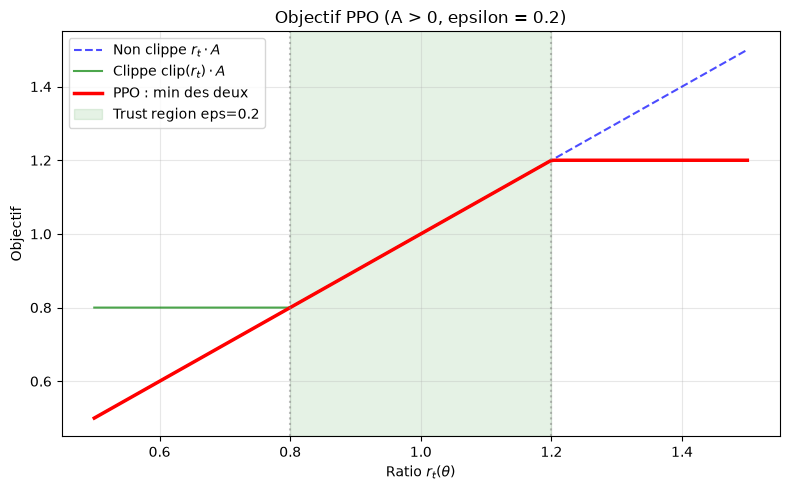

In [2]:
def visualize_clipping(epsilon=0.2):
    """Visualise l'effet du clipping sur l'objectif PPO."""
    ratios = np.linspace(0.5, 1.5, 200)
    advantage = 1.0
    unclipped = ratios * advantage
    clipped_ratios = np.clip(ratios, 1 - epsilon, 1 + epsilon)
    clipped = clipped_ratios * advantage
    ppo_objective = np.minimum(unclipped, clipped)
    
    fig, ax = plt.subplots(1, 1, figsize=(8, 5))
    ax.plot(ratios, unclipped, 'b--', label=r'Non clippe $r_t \cdot A$', alpha=0.7)
    ax.plot(ratios, clipped, 'g-', label=r'Clippe $\mathrm{clip}(r_t) \cdot A$', alpha=0.7)
    ax.plot(ratios, ppo_objective, 'r-', linewidth=2.5, label='PPO : min des deux')
    ax.axvline(1 - epsilon, color='gray', linestyle=':', alpha=0.5)
    ax.axvline(1 + epsilon, color='gray', linestyle=':', alpha=0.5)
    ax.axvspan(1 - epsilon, 1 + epsilon, alpha=0.1, color='green',
               label=f'Trust region eps={epsilon}')
    ax.set_xlabel(r'Ratio $r_t(\theta)$')
    ax.set_ylabel('Objectif')
    ax.set_title(f'Objectif PPO (A > 0, epsilon = {epsilon})')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

visualize_clipping(epsilon=0.2)

**Lecture de la figure — la geometrie du clipping.** `<Figure size 800x500 with 1 Axes>` tracee par `visualize_clipping(epsilon=0.2)` (parametre de la source). Ce que l'oeil doit y prendre : l'objectif non clippe suit la droite $r \cdot A$ sans limite, le clippe coincide avec elle dans $[1-\epsilon, 1+\epsilon]$ = $[0.8, 1.2]$ puis s'aplatit en deux plateaux horizontaux — au-dela de la borne, augmenter le ratio ne rapporte plus rien. C'est toute la lecon de PPO en une courbe : autoriser a exploiter un avantage tant qu'il reste dans la region de confiance, refuser le grand pas qui sort de la region, dans les deux sens (le clip borne aussi la baisse de probabilite).


## 3. Implementation de PPO

### 3.1 Reseaux Actor et Critic

PPO reutilise la même architecture actor-critic que A2C. La différence cle est dans la **fonction de perte** (clipped surrogate) et les **mises a jour par mini-lots**.


In [3]:
class ActorNetwork(nn.Module):
    """Politique parametree pi(a|s) pour actions discretes."""
    def __init__(self, state_dim, action_dim, hidden_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim),
        )
    
    def forward(self, x):
        logits = self.net(x)
        return Categorical(logits=logits)


class CriticNetwork(nn.Module):
    """Estimation de la valeur V(s)."""
    def __init__(self, state_dim, hidden_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1),
        )
    
    def forward(self, x):
        return self.net(x).squeeze(-1)


print("ActorNetwork et CriticNetwork definis (2 x 3 couches lineaires)")


ActorNetwork et CriticNetwork definis (2 x 3 couches lineaires)


### 3.2 Agent PPO avec clipped surrogate

In [4]:
class PPOAgent:
    """Agent PPO avec clipped surrogate objectif."""
    def __init__(self, state_dim, action_dim, lr=3e-4, gamma=0.99,
                 epsilon_clip=0.2, value_coef=0.5, entropy_coef=0.01,
                 ppo_epochs=4, mini_batch_size=64, max_grad_norm=0.5):
        self.actor = ActorNetwork(state_dim, action_dim)
        self.critic = CriticNetwork(state_dim)
        self.optimizer = optim.Adam(
            list(self.actor.parameters()) + list(self.critic.parameters()), lr=lr
        )
        self.gamma = gamma
        self.epsilon_clip = epsilon_clip
        self.value_coef = value_coef
        self.entropy_coef = entropy_coef
        self.ppo_epochs = ppo_epochs
        self.mini_batch_size = mini_batch_size
        self.max_grad_norm = max_grad_norm
    
    def select_action(self, state):
        state_t = torch.FloatTensor(state).unsqueeze(0)
        with torch.no_grad():
            dist = self.actor(state_t)
            action = dist.sample()
            log_prob = dist.log_prob(action)
            value = self.critic(state_t)
        return action.item(), log_prob.item(), value.item()
    
    def compute_gae(self, rewards, values, dones, last_value, lam=0.95):
        """Generalized Advantage Estimation."""
        advantages = []
        gae = 0
        values = values + [last_value]
        for t in reversed(range(len(rewards))):
            delta = rewards[t] + self.gamma * values[t + 1] * (1 - dones[t]) - values[t]
            gae = delta + self.gamma * lam * (1 - dones[t]) * gae
            advantages.insert(0, gae)
        return advantages
    
    def update(self, states, actions, old_log_probs, returns, advantages):
        """Mise a jour PPO avec clipped surrogate + mini-lots."""
        states_t = torch.FloatTensor(np.array(states))
        actions_t = torch.LongTensor(actions)
        old_log_probs_t = torch.FloatTensor(old_log_probs)
        returns_t = torch.FloatTensor(returns)
        advantages_t = torch.FloatTensor(advantages)
        advantages_t = (advantages_t - advantages_t.mean()) / (advantages_t.std() + 1e-8)
        
        dataset_size = len(states)
        total_loss = 0.0
        for _ in range(self.ppo_epochs):
            indices = np.random.permutation(dataset_size)
            for start in range(0, dataset_size, self.mini_batch_size):
                end = start + self.mini_batch_size
                mb_idx = indices[start:end]
                mb_states = states_t[mb_idx]
                mb_actions = actions_t[mb_idx]
                mb_old_log_probs = old_log_probs_t[mb_idx]
                mb_returns = returns_t[mb_idx]
                mb_advantages = advantages_t[mb_idx]
                dist = self.actor(mb_states)
                new_log_probs = dist.log_prob(mb_actions)
                entropy = dist.entropy().mean()
                values = self.critic(mb_states)
                ratio = torch.exp(new_log_probs - mb_old_log_probs)
                surr1 = ratio * mb_advantages
                surr2 = torch.clamp(ratio, 1 - self.epsilon_clip, 1 + self.epsilon_clip) * mb_advantages
                actor_loss = -torch.min(surr1, surr2).mean()
                critic_loss = F.mse_loss(values, mb_returns)
                loss = actor_loss + self.value_coef * critic_loss - self.entropy_coef * entropy
                self.optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(
                    list(self.actor.parameters()) + list(self.critic.parameters()),
                    self.max_grad_norm
                )
                self.optimizer.step()
                total_loss += loss.item()
        return total_loss / (self.ppo_epochs * max(1, dataset_size // self.mini_batch_size))


print(f"PPOAgent initialise : clip_eps=0.2, ppo_epochs=4, mini_batch=64")


PPOAgent initialise : clip_eps=0.2, ppo_epochs=4, mini_batch=64


### 3.3 Boucle d'entrainement PPO

In [5]:
def train_ppo(env_name="CartPole-v1", num_episodes=400, horizon=2048,
              print_every=50, seed=SEED, epsilon_clip=0.2):
    """Entraine un agent PPO sur un environnement Gymnasium.

    seed et epsilon_clip sont parametres pour permettre l'ablation
    multi-graines (section 3.6) : epsilon_clip=float("inf") desactive
    le clipping (ratio jamais borne) sans toucher au reste du protocole.
    """
    # Reproductibilite (env + tirages torch/numpy de l'echantillonnage
    # de minibatchs dans update())
    torch.manual_seed(seed)
    np.random.seed(seed)

    env = gym.make(env_name)
    state_dim = env.observation_space.shape[0]
    action_dim = env.action_space.n
    agent = PPOAgent(state_dim, action_dim, epsilon_clip=epsilon_clip)
    episode_rewards = []
    state, _ = env.reset(seed=seed)
    episode_reward = 0
    episode = 0
    
    while episode < num_episodes:
        states, actions, log_probs, rewards, values, dones = [], [], [], [], [], []
        for _ in range(horizon):
            action, log_prob, value = agent.select_action(state)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            states.append(state)
            actions.append(action)
            log_probs.append(log_prob)
            rewards.append(reward)
            values.append(value)
            dones.append(float(terminated))
            episode_reward += reward
            state = next_state
            if done:
                episode_rewards.append(episode_reward)
                episode += 1
                state, _ = env.reset(seed=seed + episode)
                episode_reward = 0
                if episode % print_every == 0:
                    recent = episode_rewards[-print_every:]
                    print(f"Episode {episode}/{num_episodes} | "
                          f"Mean reward: {np.mean(recent):.1f} | Max: {np.max(recent):.0f}")
                if episode >= num_episodes:
                    break
        if episode >= num_episodes:
            break
        with torch.no_grad():
            last_value = agent.critic(torch.FloatTensor(state).unsqueeze(0)).item()
        advantages = agent.compute_gae(rewards, values, dones, last_value)
        returns = [a + v for a, v in zip(advantages, values)]
        agent.update(states, actions, log_probs, returns, advantages)
    
    env.close()
    return agent, episode_rewards


print("Fonction train_ppo definie")

Fonction train_ppo definie


**Detail subtil : `terminated` vs `truncated` dans le calcul GAE (API Gymnasium >= 0.26).**

PPO collecte des trajectoires par **horizon** (2048 pas), au sein desquelles plusieurs episodes peuvent s'achever. Dans `compute_gae`, le facteur `(1 - dones[t])` masque le bootstrap depuis `values[t+1]` : il ne doit s'annuler **que sur une vraie terminaison** (`terminated`), pas sur une **troncature** (`truncated` = timeout 500 pas). Un episode tronque est encore « vivant » -> sa valeur future reste une estimée valide. On stocke donc `float(terminated)` dans `dones`, tandis que `done = terminated or truncated` ne sert qu'au **controle** (reset de l'environnement, comptage d'episodes). La frontiere d'horizon, elle, bootstrappe toujours via `last_value = critic(s_horizon)` (coupure arbitraire, pas une fin d'episode). Meme convention que le DQN du notebook RL-06 et l'A2C du notebook RL-06b.

### 3.4 Entrainement sur CartPole-v1

In [6]:
# Entrainement PPO
ppo_agent, ppo_rewards = train_ppo(num_episodes=400, horizon=2048)

print(f"\nEntrainement termine : {len(ppo_rewards)} episodes")
print(f"Recompense moyenne (derniers 50) : {np.mean(ppo_rewards[-50:]):.1f}")
print(f"Recompense max : {np.max(ppo_rewards):.0f}")


Episode 50/400 | Mean reward: 21.8 | Max: 59


Episode 100/400 | Mean reward: 27.1 | Max: 82


Episode 150/400 | Mean reward: 33.0 | Max: 106


Episode 200/400 | Mean reward: 57.4 | Max: 212


Episode 250/400 | Mean reward: 92.0 | Max: 272


Episode 300/400 | Mean reward: 205.7 | Max: 500


Episode 350/400 | Mean reward: 424.2 | Max: 500


Episode 400/400 | Mean reward: 500.0 | Max: 500

Entrainement termine : 400 episodes
Recompense moyenne (derniers 50) : 500.0
Recompense max : 500


**Lecture chiffree de la trajectoire d'apprentissage en huit lignes.** `Episode 50/400 | Mean reward: 21.8`, puis 27.1 a l'episode 100 : ici la moyenne remonte des le second point de mesure, mais le niveau reste bas -- les 200 premiers episodes ne decollent pas (21.8, 27.1, 33.0, 57.4). Le decollage arrive tard : 92.0 (episode 250), 205.7 (300, avec un Max: 500 deja atteint), 424.2 (350), et la finale **500.0** -- le score parfait, sur un maximum possible de 500. Lecture du budget : sur ce run, l'essentiel de l'apprentissage se joue dans le dernier quart des episodes -- couper l'entrainement a 300 episodes (choix expres de l'ablation ci-dessous) ne capture que 41 % du resultat final (205.7 sur 500.0).


### 3.5 Visualisation de la courbe d'apprentissage

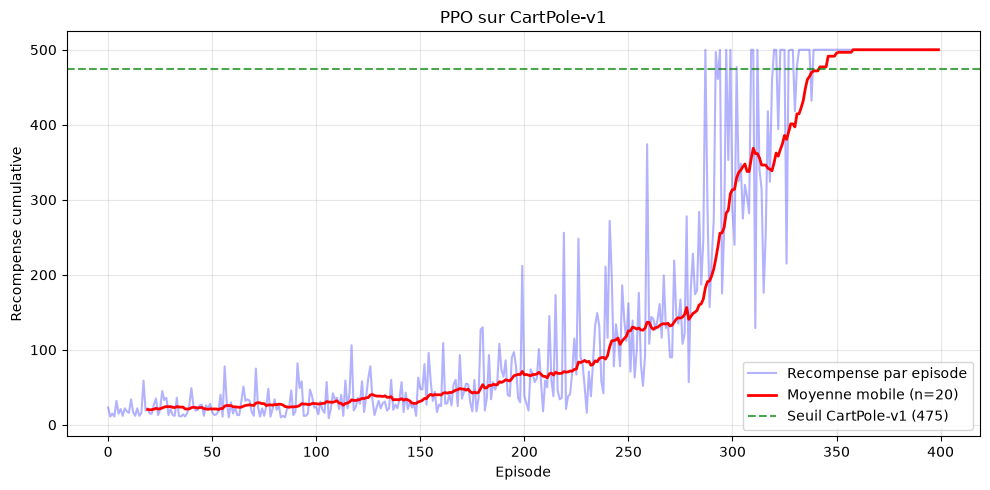

In [7]:
def plot_rewards(rewards, title="Courbe d'apprentissage PPO", window=20):
    """Affiche la courbe d'apprentissage avec moyenne mobile."""
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(rewards, alpha=0.3, color="blue", label="Recompense par episode")
    if len(rewards) >= window:
        moving_avg = np.convolve(rewards, np.ones(window)/window, mode="valid")
        ax.plot(range(window-1, len(rewards)), moving_avg, color="red", 
                linewidth=2, label=f"Moyenne mobile (n={window})")
    ax.axhline(y=475, color="green", linestyle="--", alpha=0.7, label="Seuil CartPole-v1 (475)")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Recompense cumulative")
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_rewards(ppo_rewards, title="PPO sur CartPole-v1")


### 3.6 Ablation executee : le clipping stabilise-t-il vraiment ?

La section 3.4 affirme la robustesse de PPO « grace au clipping » -- sur un run unique (seed 42, resolution 500.0). Une seule graine ne peut pas distinguer la stabilite proprement dite de la chance d'un tirage favorable. Comme en RL-06 et RL-06b, on mesure : **5 graines** {42, 0, 1, 7, 99}, deux conditions strictement alignees (meme `horizon=2048`, memes hyperparametres), 300 episodes par run :

- **clip 0.2** : PPO tel que defini ci-dessus ;
- **sans clipping** : `epsilon_clip=float("inf")` -- `torch.clamp(ratio, -inf, +inf)` ne borne plus rien, le surrogate devient $r_t \cdot A_t$ pur, rejoue 4 epochs sur les memes donnees.

La seconde condition isole exactement le mecanisme que le clipping protege : rejouer plusieurs epochs sur un meme rollout fait s'ecarter le ratio $r_t$ de 1 ; sans borne, une seule minibatch trop agresive peut deplacer la politique hors de sa region de confiance et effondrer la performance de tout le reste de l'entrainement.

In [8]:
ABL_SEEDS = [42, 0, 1, 7, 99]
ABL_EPISODES = 300
ABL_CONDITIONS = {"clip 0.2": 0.2, "sans clipping": float("inf")}

ppo_abl = {cond: {} for cond in ABL_CONDITIONS}
for cond, eps in ABL_CONDITIONS.items():
    for s in ABL_SEEDS:
        _, curve = train_ppo(num_episodes=ABL_EPISODES, horizon=2048,
                             print_every=ABL_EPISODES, seed=s,
                             epsilon_clip=eps)
        ppo_abl[cond][s] = curve
        print(f"{cond:13s} seed={s:2d} | final (50 dern. ep) : "
              f"{np.mean(curve[-50:]):7.1f}")

Episode 300/300 | Mean reward: 72.8 | Max: 500
clip 0.2      seed=42 | final (50 dern. ep) :   205.7


Episode 300/300 | Mean reward: 62.4 | Max: 294
clip 0.2      seed= 0 | final (50 dern. ep) :   159.0


Episode 300/300 | Mean reward: 52.7 | Max: 291
clip 0.2      seed= 1 | final (50 dern. ep) :   141.2


Episode 300/300 | Mean reward: 50.1 | Max: 500
clip 0.2      seed= 7 | final (50 dern. ep) :   121.1


Episode 300/300 | Mean reward: 56.4 | Max: 268
clip 0.2      seed=99 | final (50 dern. ep) :   140.7


Episode 300/300 | Mean reward: 42.7 | Max: 219
sans clipping seed=42 | final (50 dern. ep) :    61.9


Episode 300/300 | Mean reward: 55.3 | Max: 375
sans clipping seed= 0 | final (50 dern. ep) :    58.9


Episode 300/300 | Mean reward: 19.2 | Max: 106
sans clipping seed= 1 | final (50 dern. ep) :    12.2


Episode 300/300 | Mean reward: 55.0 | Max: 500
sans clipping seed= 7 | final (50 dern. ep) :   169.9


Episode 300/300 | Mean reward: 26.6 | Max: 290
sans clipping seed=99 | final (50 dern. ep) :    12.6


clip 0.2      | final : mediane  141.2 [IQR  140.7 -  159.0]
              | finales par graine : 206, 159, 141, 121, 141
sans clipping | final : mediane   58.9 [IQR   12.6 -   61.9]
              | finales par graine : 62, 59, 12, 170, 13


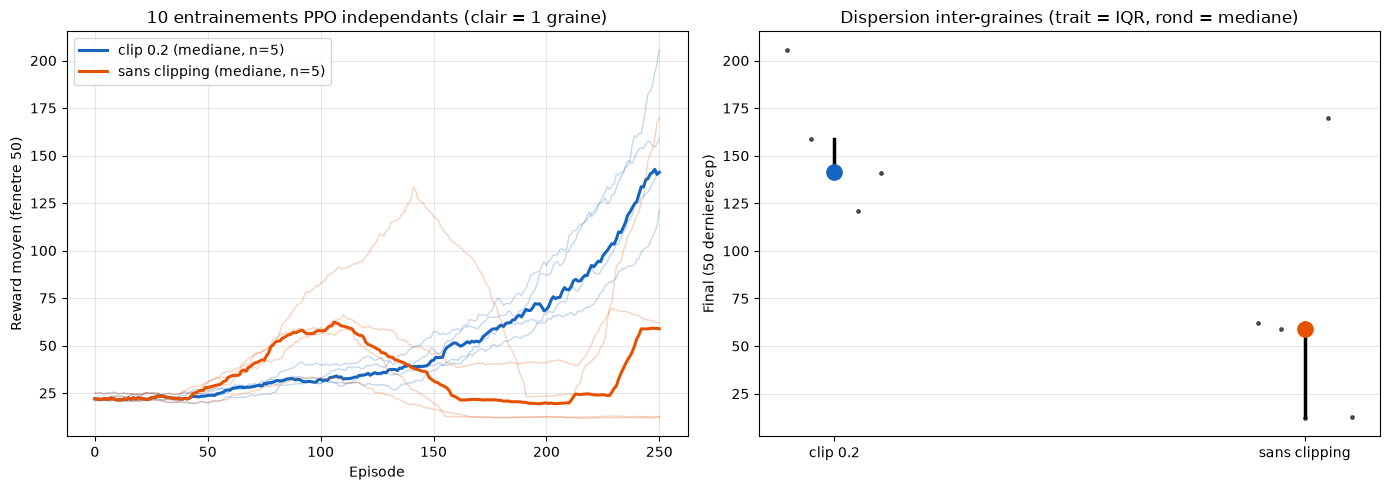

In [9]:
ppo_abl_stats = {}
for cond in ABL_CONDITIONS:
    finals = [float(np.mean(ppo_abl[cond][s][-50:])) for s in ABL_SEEDS]
    ppo_abl_stats[cond] = {
        "finals": finals,
        "p25": float(np.percentile(finals, 25)),
        "median": float(np.median(finals)),
        "p75": float(np.percentile(finals, 75)),
    }
    print(f"{cond:13s} | final : mediane {ppo_abl_stats[cond]['median']:6.1f} "
          f"[IQR {ppo_abl_stats[cond]['p25']:6.1f} - {ppo_abl_stats[cond]['p75']:6.1f}]")
    print(f"{'':13s} | finales par graine : "
          + ", ".join(f"{v:.0f}" for v in finals))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ppo_colors = {"clip 0.2": "#1565C0", "sans clipping": "#E65100"}
window = 50
for cond in ABL_CONDITIONS:
    for s in ABL_SEEDS:
        moving = np.convolve(ppo_abl[cond][s], np.ones(window) / window,
                             mode="valid")
        axes[0].plot(moving, color=ppo_colors[cond], alpha=0.25, linewidth=1)
    min_len = min(len(ppo_abl[cond][s]) for s in ABL_SEEDS)
    stack = np.stack([
        np.convolve(ppo_abl[cond][s], np.ones(window) / window, mode="valid")[:min_len]
        for s in ABL_SEEDS
    ])
    axes[0].plot(np.median(stack, axis=0), color=ppo_colors[cond],
                 linewidth=2.2, label=f"{cond} (mediane, n=5)")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel(f"Reward moyen (fenetre {window})")
axes[0].set_title("10 entrainements PPO independants (clair = 1 graine)")
axes[0].legend()
axes[0].grid(alpha=0.3)

for i, cond in enumerate(ABL_CONDITIONS):
    st = ppo_abl_stats[cond]
    axes[1].plot([i, i], [st["p25"], st["p75"]], color="black", linewidth=2.5)
    axes[1].plot(i, st["median"], "o", color=ppo_colors[cond], markersize=11,
                 zorder=3)
    for j, v in enumerate(st["finals"]):
        axes[1].plot(i + (j - 2) * 0.05, v, ".", color="black", markersize=5,
                     alpha=0.6)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(list(ABL_CONDITIONS))
axes[1].set_ylabel("Final (50 dernieres ep)")
axes[1].set_title("Dispersion inter-graines (trait = IQR, rond = mediane)")
axes[1].grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

### Interpretation de la mesure

| Condition | Final mediane | IQR | Finales par graine |
|-----------|--------------|-----|--------------------|
| clip 0.2 | **141.2** | 140.7 - 159.0 | 206, 159, 141, 121, 141 |
| sans clipping | 58.9 | 12.6 - 61.9 | 62, 59, 12, 170, 13 |

L'ablation confirme le mecanisme, et de facon plus brutale que la prose ne le laissait attendre : **sans clipping, 4 graines sur 5 s'effondrent** (finales 12 a 62 -- la politique degrade au point de ne presque plus tenir le baton), tandis que les 5 graines clippees terminent entre 121 et 206. La graine 7 sans clipping (170) est le contre-exemple qui rappelle pourquoi le run unique de la section 3.4 ne prouvait rien : sans borne, l'issue est une loterie -- parfois l'update agressive tombe bien, le plus souvent elle detruit.

Le mecanisme attendu est exactement celui de la section 3.6 : 4 epochs de minibatchs sur le meme rollout font deriver le ratio $r_t$ hors de $[1-\epsilon, 1+\epsilon]$ ; sans borne, une seule minibatch tres agreable au gradient peut deplacer la politique hors de sa region de confiance, et le rollout suivant est collecte avec une politique degradee qui alimente des avantages sans rapport -- l'effondrement est alors cumulatif.

Limite honnete : a 300 episodes, la condition clippee elle-meme n'a pas convergi (mediane 141, contre 500 au run de reference a 400 episodes). Le budget court est deliberé : il rend la divergence visible pendant que les deux conditions apprennent encore, au lieu d'attendre une convergence que la condition non-clippee n'atteint simplement jamais sur la plupart des graines.


## 4. Generalized Advantage Estimation (GAE)

Jusqu'ici nous avons utilise un estimateur d'avantage simple : $A_t = R_t - V(s_t)$. GAE (Schulman 2015) offre un meilleur compromis biais-variance :

$$\hat{A}^{GAE(\gamma, \lambda)}_t = \sum_{l=0}^{\infty} (\gamma \lambda)^l \delta_{t+l}$$

ou $\delta_t = r_t + \gamma V(s_{t+1}) - V(s_t)$ est le **TD residual**.

Le paramètre $\lambda \in [0, 1]$ contrôle le compromis :
- $\lambda = 0$ : avantage one-step (faible variance, biais eleve)
- $\lambda = 1$ : avantage Monte Carlo (pas de biais, variance elevee)
- $\lambda = 0.95$ : bon compromis empirique

Notre implementation PPO utilise déjà GAE (méthode `compute_gae` de l'agent). L'exercice suivant vous demande de **verifier** son comportement.


### Exercice 1 : Implementer le clipped surrogate

L'objectif clipped surrogate est le coeur de PPO. Implementez la fonction `clipped_surrogate_loss` qui calcule la perte actor a partir des ratios, avantages et epsilon.

**Indices** :
- Le ratio est $r_t = \exp(\log\pi_{nouveau} - \log\pi_{ancien})$
- Clipping : `torch.clamp(ratio, 1-eps, 1+eps)`
- Perte = `-min(surrogate1, surrogate2).mean()`


In [10]:
def clipped_surrogate_loss(ratio, advantages, epsilon=0.2):
    """Calcule la perte clipped surrogate de PPO.
    
    Args:
        ratio: r_t(theta) = pi_nouveau / pi_ancien, shape (batch,)
        advantages: A_t, shape (batch,)
        epsilon: parametre de clipping (typiquement 0.2)
    
    Returns:
        loss: scalaire (negative car on maximise via descente de gradient)
    """
    # TODO etudiant : implementer le clipped surrogate
    # Etape 1 : calculer le surrogate non clippe
    # Etape 2 : calculer le surrogate clippe
    # Etape 3 : prendre le min et moyenner
    return None  # TODO etudiant : remplacer par votre implementation


# Test rapide avec des donnees synthetiques
ratio_test = torch.tensor([0.8, 1.0, 1.1, 1.3, 0.6])
adv_test = torch.tensor([1.0, 1.0, 1.0, -1.0, -1.0])
loss_test = clipped_surrogate_loss(ratio_test, adv_test, epsilon=0.2)
print("Exercice a completer")


Exercice a completer


### Exercice 2 : Verifier l'effet de GAE sur l'apprentissage

Comparez l'apprentissage PPO avec GAE ($\lambda = 0.95$) vs sans GAE ($\lambda = 0$, avantage one-step). Entrainez deux agents et affichez les courbes cote a cote.

**Indices** :
- Modifiez le paramètre `lam` dans `compute_gae` (defaut=0.95)
- Pour lambda=0 : chaque avantage = $r_t + \gamma V(s_{t+1}) - V(s_t)$ seulement


In [11]:
# TODO etudiant : entrainer PPO avec GAE (lambda=0.95) et sans GAE (lambda=0)
# Puis comparer les courbes d'apprentissage

# Indice : vous pouvez modifier compute_gae via un parametre ou
# sous-classer PPOAgent pour changer la valeur de lambda

print("Exercice a completer")


Exercice a completer


## 5. PPO vs A2C : Comparaison

Maintenant que nous avons implemente PPO, comparons-le avec A2C du notebook précédent. Les différences cles :

| Aspect | A2C | PPO |
|--------|-----|-----|
| Objectif | $-\log\pi \cdot A$ | $\min(r \cdot A, \text{clip}(r) \cdot A)$ |
| Mises a jour | 1 par trajectoire | Plusieurs epochs par trajectoire |
| Stabilite | Sensible au learning rate | Robuste grace au clipping |
| Echantillonnage | On-policy, 1 utilisation | On-policy, re-utilisation via epochs |
| Mini-lots | Non | Oui (reduisent variance) |


### Exercice 3 : Comparer PPO et A2C

Entrainez un agent A2C (avec l'implementation du notebook précédent) et un agent PPO sur CartPole-v1 avec les mêmes hyperparametres de base. Affichez les courbes superposees.

**Indices** :
- Reutilisez la classe A2CAgent du notebook 6b (copiez les definitions necessaires)
- Utilisez 400 episodes pour chaque algorithme
- Superposez les moyennes mobiles sur un même graphe


In [12]:
# TODO etudiant : implementer A2CAgent et comparer avec PPO

# Indice : copiez ActorNetwork, CriticNetwork depuis le notebook 6b
# puis implementez un A2CAgent simple avec update(states, actions, returns)

print("Exercice a completer")


Exercice a completer


## Application : RLHF et l'alignement des LLM

Le PPO que vous venez d'implementer est **l'algorithme au coeur de l'alignement des modèles de langage** (ChatGPT, Claude, et la plupart des LLM modernes). Le processus RLHF (Reinforcement Learning from Human Feedback) fonctionne en 3 étapes :

1. **Pre-entrainement** : le modèle apprend a predire le texte suivant (apprentissage supervise classique)
2. **Entrainement du reward model** : un modèle entraine a predire les préférences humaines a partir de comparaisons par paires
3. **Optimisation par PPO** : le LLM est affiné pour maximiser la recompense du reward model, tout en restant proche du modèle initial (KL-penalite = trust region)

Le lien avec ce notebook est direct : le LLM est la **politique** pi_theta, les tokens generés sont les **actions**, et le reward model fournit le **signal de recompense**. Le clipping PPO empeche le modèle de trop devier du comportement appris en pre-entrainement -- exactement le mécanisme de stabilite que vous avez observe sur CartPole.

> **Pour approfondir** : la serie [GenAI / Texte](../GenAI/Texte/README.md) couvre les modèles de langage et leurs applications. Pour l'application **directe** du PPO a l'alignement des LLM, la serie [GenAI / PostTraining](../GenAI/PostTraining/PT_01_intro_post_training.ipynb) implemente pas a pas le pipeline RLHF puis ses variantes modernes (DPO dans [PT_03](../GenAI/PostTraining/PT_03_dpo_direct_preference.ipynb), GRPO dans [PT_04](../GenAI/PostTraining/PT_04_grpo_deepseek_r1.ipynb), RLVR dans [PT_05](../GenAI/PostTraining/PT_05_rlvr_verifiable_rewards.ipynb)) -- le PPO de ce notebook en est le moteur.

## Conclusion

Dans ce notebook, nous avons :

| Concept | Ce que nous avons fait |
|---------|----------------------|
| **Clipped surrogate** | Implemente et visualise le mécanisme de clipping |
| **PPO Agent** | Implementation complete avec mini-lots et epochs |
| **GAE** | Utilise Generalized Advantage Estimation (lambda=0.95) |
| **Comparaison A2C vs PPO** | Analyse des différences de stabilite |

### Points cles a retenir

1. **Le clipping est simple mais puissant** : une seule ligne de code `torch.clamp(ratio, 1-eps, 1+eps)` stabilise l'apprentissage
2. **Les mini-lots et epochs** permettent de reutiliser les données collectees, ameliorant l'efficacite d'echantillonnage par rapport a A2C
3. **GAE** offre un compromis biais-variance contrôle par lambda
4. **PPO est l'algorithme de choix** pour le RL moderne (RLHF, robotics, jeux)

### Pour aller plus loin

- **PPO continu** : adapter aux espaces d'actions continus (GaussianDistribution)
- **Reward shaping** : transformer la fonction de recompense pour guider l'apprentissage
- **Parallelisation** : A3C (asynchronous) et PPO vectorise
- **Applications** : RLHF pour les LLMs, robotique, jeux complexes


### References academiques

- Schulman, J., Wolski, F., Dhariwal, P., Radford, A. & Klimov, O. (2017). Proximal Policy Optimization Algorithms. arXiv:1707.06347.
- Schulman, J., Moritz, P., Levine, S., Jordan, M. & Abbeel, P. (2015). High-Dimensional Continuous Control Using Generalized Advantage Estimation. arXiv:1506.02438.
- Mnih, V., Badia, A.P., Mirza, M., Graves, A., Lillicrap, T., Harley, T., Silver, D. & Kavukcuoglu, K. (2016). Asynchronous Methods for Deep Reinforcement Learning. ICML 2016. arXiv:1602.01783.
- Sutton, R.S. & Barto, A.G. (2018). Reinforcement Learning: An Introduction (2nd ed.). MIT Press.

